# Shallow Velocity Model (GTL)

This notebook is used to plot cross sections for the shallow velocity model to improvement of LA basin for UCVM

### Load Packages

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import math
import matplotlib.colors as mcolors
from matplotlib import rcParams as rc
import matplotlib
import matplotlib.tri as tri
from pyproj import Proj, transform
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
from pickle import dump, load
import linear_operator
from scipy.interpolate import griddata


configs = {
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'font.sans-serif': ['Times New Roman'],
     #'font.sans-serif': ['Microsoft YaHei', 'SimHei', 'Arial', 'Liberation Sans', 'sans-serif'],
    #'font.sans-serif': ['Palatino Linotype', 'Microsoft YaHei', 'SimHei', 'Arial', 'Liberation Sans', 'sans-serif'],
    'axes.grid': True,
    'grid.alpha': 0.5,
    'grid.linestyle': '--',
    'mathtext.fontset': "cm",
    # 'mathtext.rm': "asana math",
    # 'mathtext.cal': "asana math",
    "font.size": 20,
    # 'axes.labelsize': 'large',
    # 'axes.labelpad': 8.0,
    # 'xtick.major.pad': 9.0,
}
rc.update(configs)

In [2]:
norm = mcolors.Normalize(vmin=150., vmax=2000.)  
cmap = matplotlib.colormaps.get_cmap("coolwarm")
red_color = cmap(0.9)
blue_color = cmap(0.1)
gray_color = cmap(0.5)

color_maps = {
    "input": gray_color,
    "Expected": red_color,
    "Predicted": blue_color,
}

### Define Variables

In [3]:
# define cross-section location
fn_crssect_loc   = '../Data/Raw_data/cross_section.csv'
crssect_loc = pd.read_csv(fn_crssect_loc)

#get corresponding coordinates
id = 1
def get_crssect_coords(crssect_loc, target_id):
    subset = crssect_loc[crssect_loc['cross_id'] == target_id]
    crssect_str = subset.iloc[0][['x', 'y']].tolist()
    crssect_end = subset.iloc[1][['x', 'y']].tolist()
    return crssect_str, crssect_end

crssect_str, crssect_end = get_crssect_coords(crssect_loc, id)


In [4]:
#define corss-section
name_crssect = 'Cross Section ' + str(id)
fname_crssect = name_crssect.lower().replace(' ','_')

#cross-section extents
crssect_depth = [0, 500]

#descritization
crssect_npt_xy = 100
crssect_npt_z  = 20
crs_grid = []

#model directory
dir_model = './'

#gtl cross section
fn_gtl = '../Data/Raw_data/GTL/transect_curvi_CVMSI+SGSB+ElyGTLvarzt_CS'+str(id)+'.txt'

#model column names (input, output)
cn_x = ['vs_depth','Z_2.5','elevation','surf_elevation','easting','northing'] #output
cn_y = 'diff'                                                     #input

#define output directories
dir_out = '../Data/Vel_data/'
dir_fig = '../Data/Figure/'

### Cross-Section Geometry

In [5]:
#create x,y,z grid
points_xy = np.linspace(crssect_str, crssect_end, crssect_npt_xy)
points_z = np.linspace(crssect_depth[0], crssect_depth[1], crssect_npt_z)

for x, y in points_xy:
    for z in points_z:
        crs_grid.append([x, y, z])

#wite geometry for ucvm query
with open(dir_out+'Cross_section_input'+'/'+fname_crssect+'_ucvm_input.txt', "w", encoding="utf-8") as file:
    for i in crs_grid:
        file.write(" ".join(map(str, i)) + "\n") 

### Load UCVM Model

In [6]:
df_ucvm = pd.read_csv(
    dir_out + 'Cross_section_results/' + str(id) + '_vs_data_cross_section.txt',
    sep=',')
df_ucvm

,long,lat,vs_depth,surf_elevation,vs30,cvm,cvm_vp,cvm_vs,cvm_dens,gtl,...,vp,vs,dens,easting,northing,distance,Z_2.5,basin_idnum,predict_diff,predict_vs
0,-117.2946,34.1861,0.000,522.347,579.862,cvms5,1310.405,825.000,2017.052,none,...,1310.405,825.000,2017.052,472853.756347,3.782830e+06,0.000000,1520.0,4,-1.485443e+00,186.781623
1,-117.2946,34.1861,26.316,522.347,579.862,cvms5,1453.439,904.240,2058.210,none,...,1453.439,904.240,2058.210,472853.756347,3.782830e+06,0.000000,1520.0,4,-6.421718e-01,475.764523
2,-117.2946,34.1861,52.632,522.347,579.862,cvms5,1596.474,983.480,2095.441,none,...,1596.474,983.480,2095.441,472853.756347,3.782830e+06,0.000000,1520.0,4,-5.094729e-01,590.886785
3,-117.2946,34.1861,78.947,522.347,579.862,cvms5,1739.508,1062.720,2129.011,none,...,1739.508,1062.720,2129.011,472853.756347,3.782830e+06,0.000000,1520.0,4,-4.296771e-01,691.532263
4,-117.2946,34.1861,105.263,522.347,579.862,cvms5,1882.542,1141.959,2159.192,none,...,1882.542,1141.959,2159.192,472853.756347,3.782830e+06,0.000000,1520.0,4,-1.794815e-01,954.339038
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,-117.2946,34.0531,394.737,305.461,286.087,cvms5,4075.404,2323.577,2387.869,none,...,4075.404,2323.577,2387.869,472811.223522,3.768083e+06,14747.197957,460.0,4,-2.475021e-18,2323.577000
1996,-117.2946,34.0531,421.053,305.461,286.087,cvms5,4239.315,2419.438,2402.416,none,...,4239.315,2419.438,2402.416,472811.223522,3.768083e+06,14747.197957,460.0,4,-3.312799e-22,2419.438000
1997,-117.2946,34.0531,447.368,305.461,286.087,cvms5,4403.226,2515.299,2418.251,none,...,4403.226,2515.299,2418.251,472811.223522,3.768083e+06,14747.197957,460.0,4,-1.748544e-26,2515.299000
1998,-117.2946,34.0531,473.684,305.461,286.087,cvms5,4567.136,2611.160,2435.684,none,...,4567.136,2611.160,2435.684,472811.223522,3.768083e+06,14747.197957,460.0,4,-3.636791e-31,2611.160000


### Load GTL Model

In [7]:
df_gtl_raw = pd.read_csv(fn_gtl, sep=r'\s+', 
                      header=None,
                      names=['long','lat','vs_depth','gtl_vp','gtl_vs'])

#get UTM zone 
def longlat_to_utm(lon, lat):
    utm_zone = int((lon + 180) / 6) + 1
    proj = Proj(proj='utm', zone=utm_zone, ellps='WGS84')
    easting, northing = proj(lon, lat)
    return easting, northing

df_gtl_raw[['easting', 'northing']] = df_gtl_raw.apply(lambda row: pd.Series(longlat_to_utm(row['long'], row['lat'])), axis=1)

df_gtl_raw['distance'] = np.linalg.norm((df_gtl_raw[['easting','northing']] - df_ucvm.loc[0,['easting','northing']]).values.astype(float), 
                                     axis=1)

# Linearly interpolate the data (x, y) on a grid defined by (xi, yi).
triang = tri.Triangulation(df_gtl_raw.distance, df_gtl_raw.vs_depth)
interpolator = tri.LinearTriInterpolator(triang, df_gtl_raw.gtl_vs)

df_gtl_grid = df_ucvm[['long','lat','easting','northing','distance','vs_depth']].copy()
df_gtl_grid.loc[:,'vs'] = interpolator(df_gtl_grid.distance, df_gtl_grid.vs_depth)

### Plot for GTL model

In [8]:
distance = df_ucvm['distance'].values/1000
depth = df_ucvm['vs_depth'].values

X = np.reshape(distance, [crssect_npt_xy, crssect_npt_z]).T
Y = np.reshape(depth, [crssect_npt_xy, crssect_npt_z]).T
Z_gtl   = np.reshape(df_gtl_grid['vs'].values, [crssect_npt_xy, crssect_npt_z]).T

In [9]:
df_gtl_grid

,long,lat,easting,northing,distance,vs_depth,vs
0,-117.2946,34.1861,472853.756347,3.782830e+06,0.000000,0.000,NaN
1,-117.2946,34.1861,472853.756347,3.782830e+06,0.000000,26.316,NaN
2,-117.2946,34.1861,472853.756347,3.782830e+06,0.000000,52.632,NaN
3,-117.2946,34.1861,472853.756347,3.782830e+06,0.000000,78.947,NaN
4,-117.2946,34.1861,472853.756347,3.782830e+06,0.000000,105.263,NaN
...,...,...,...,...,...,...,...
1995,-117.2946,34.0531,472811.223522,3.768083e+06,14747.197957,394.737,NaN
1996,-117.2946,34.0531,472811.223522,3.768083e+06,14747.197957,421.053,NaN
1997,-117.2946,34.0531,472811.223522,3.768083e+06,14747.197957,447.368,NaN
1998,-117.2946,34.0531,472811.223522,3.768083e+06,14747.197957,473.684,NaN


In [10]:

valid = np.isfinite(Z_gtl)

print("Valid points:", valid.sum())
print("Total points:", Z_gtl.size)

if valid.sum() == 0:
    raise ValueError("Z_gtl contains no valid Vs values. Please check df_gtl_grid['vs'].")

Z_linear = griddata(
    points=(X[valid], Y[valid]),
    values=Z_gtl[valid],
    xi=(X, Y),
    method="linear"
)

Z_nearest = griddata(
    points=(X[valid], Y[valid]),
    values=Z_gtl[valid],
    xi=(X, Y),
    method="nearest"
)

Z_gtl_filled = np.where(
    np.isfinite(Z_linear),
    Z_linear,
    Z_nearest
)

Valid points: 1862
Total points: 2000


findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following fa

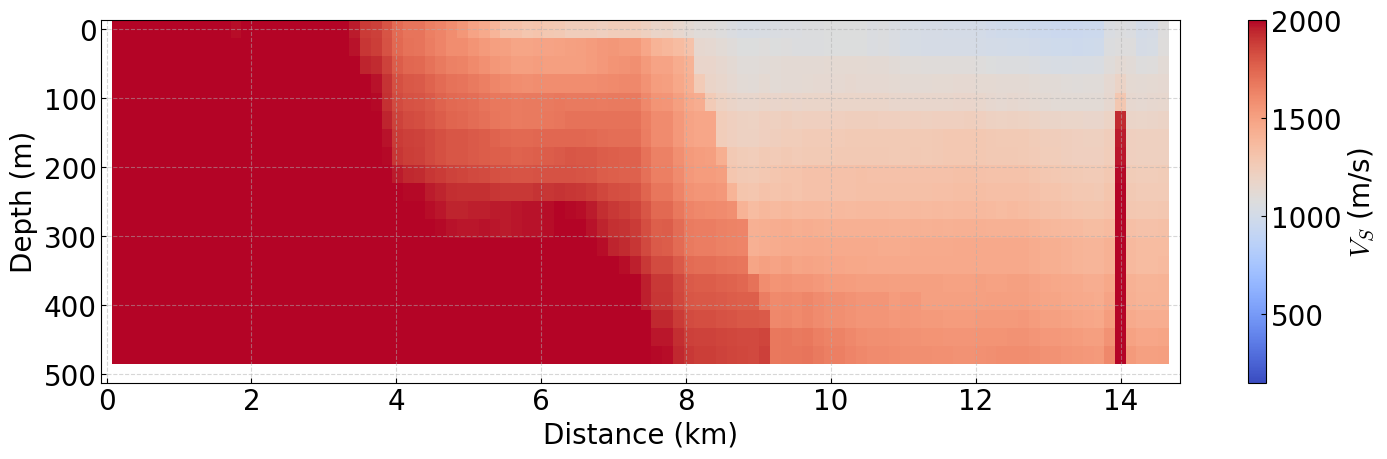

In [11]:
fig, ax = plt.subplots(figsize=(15., 5.))
c = ax.pcolormesh(X, Y, Z_gtl, cmap=cmap, norm=norm, shading='auto')
ax.set_xlabel("Distance (km)")
ax.set_ylabel("Depth (m)")
ax.invert_yaxis() 
fig.colorbar(c, ax=ax, label=r"$V_S$ (m/s)")
plt.tight_layout()
plt.show()

findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following fa

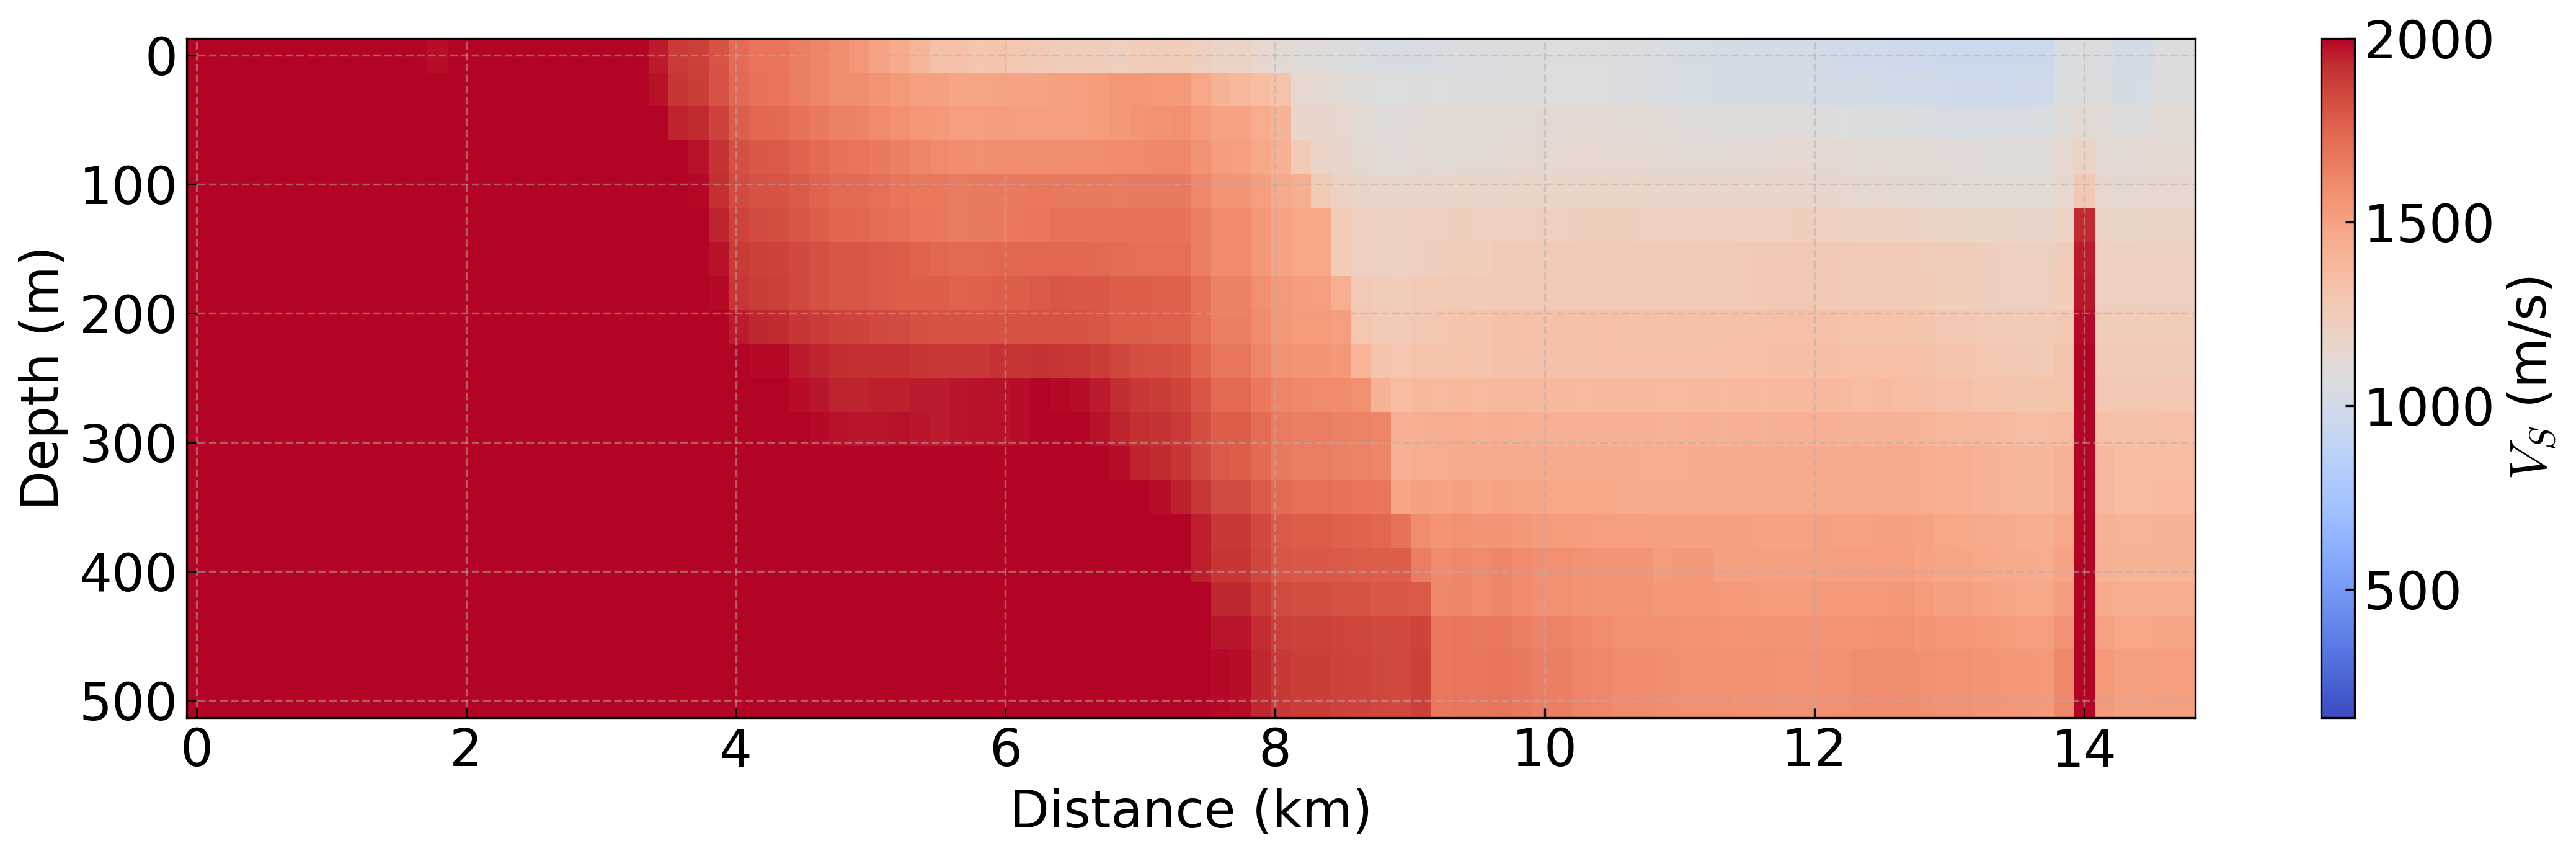

In [12]:
fig, ax = plt.subplots(figsize=(15, 5), dpi=300)

c = ax.pcolormesh(
    X,
    Y,
    Z_gtl_filled,
    cmap=cmap,
    norm=norm,
    shading="auto"
)

ax.set_xlabel("Distance (km)")
ax.set_ylabel("Depth (m)")
ax.invert_yaxis()

fig.colorbar(c, ax=ax, label=r"$V_S$ (m/s)")

plt.tight_layout()
plt.show()

### Plot for all model

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family ['Arial'] not found. Falling back t

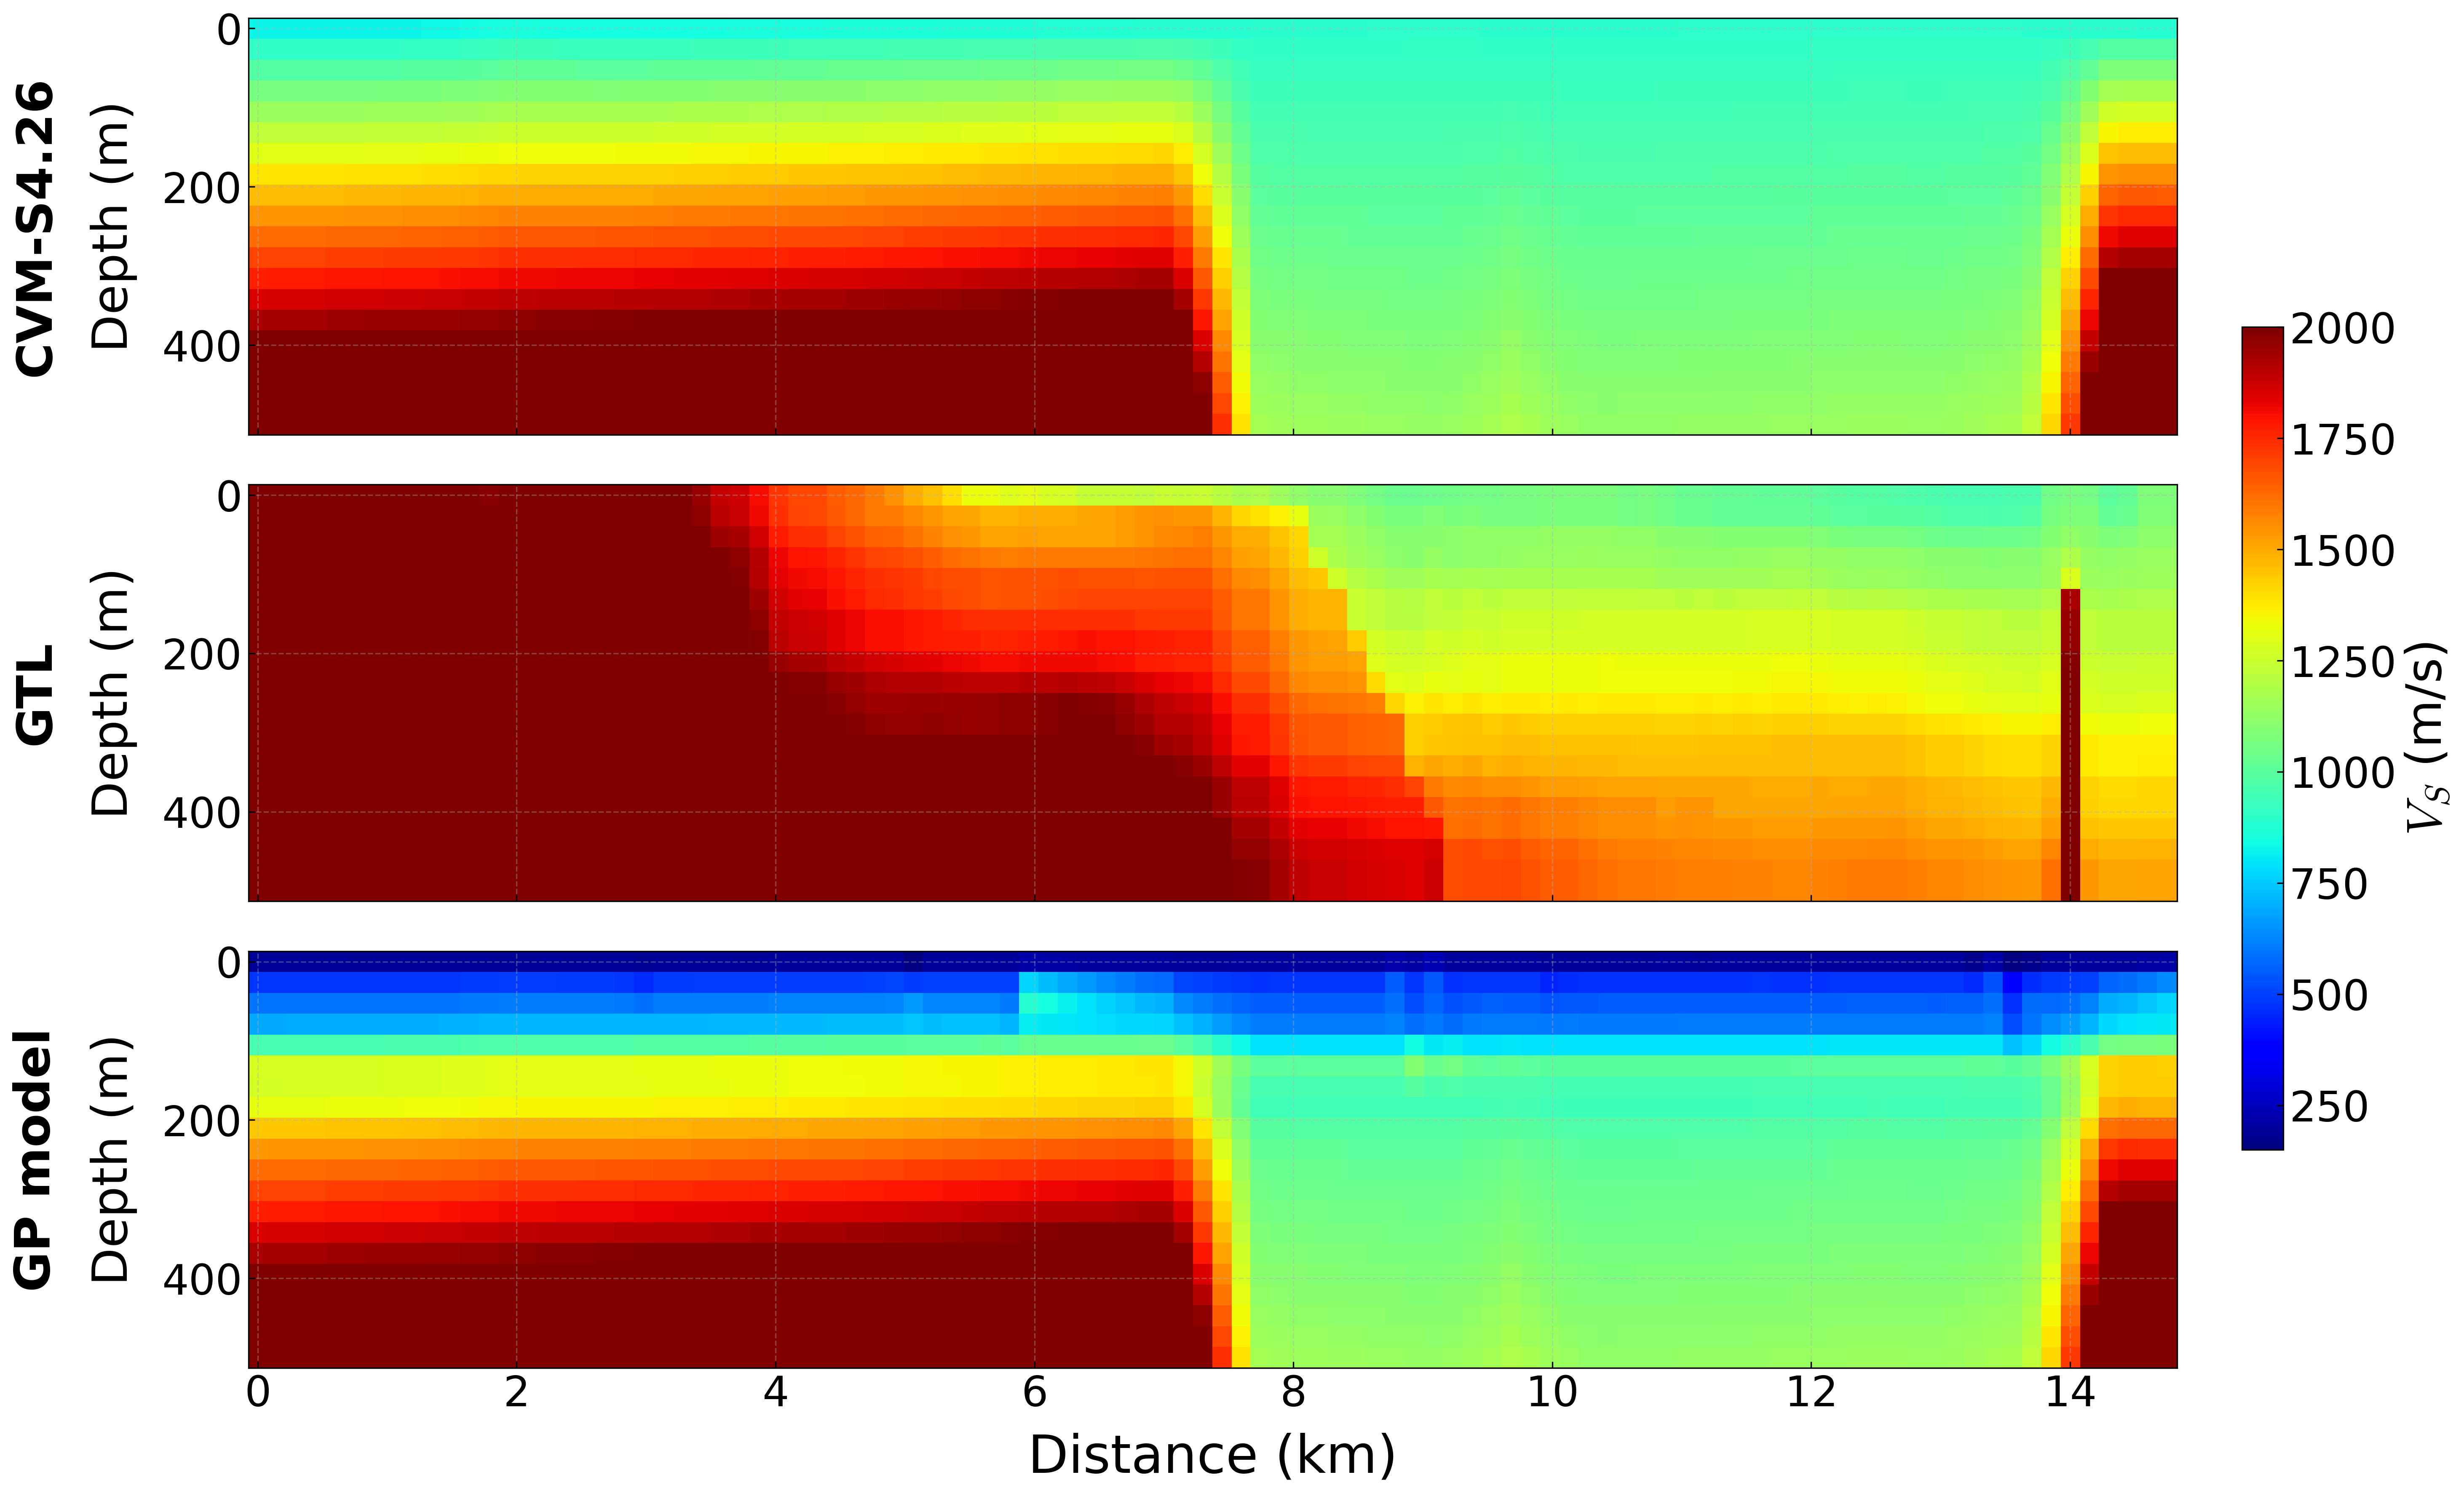

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

In [13]:
cols_numeric = [
    "distance",
    "vs_depth",
    "cvm_vs",
    "predict_vs"
]

for col in cols_numeric:
    df_ucvm[col] = pd.to_numeric(df_ucvm[col], errors="coerce")

distance = df_ucvm['distance'].values / 1000
depth = df_ucvm['vs_depth'].values

X = np.reshape(distance, [crssect_npt_xy, crssect_npt_z]).T
Y = np.reshape(depth, [crssect_npt_xy, crssect_npt_z]).T
Z_model_plot = np.reshape(df_ucvm['predict_vs'].values, [crssect_npt_xy, crssect_npt_z]).T
Z_ucvm_plot  = np.reshape(df_ucvm['vs'].values, [crssect_npt_xy, crssect_npt_z]).T
Z_gtl_plot   = Z_gtl_filled

plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 28  

vs_levels = np.array([0, 250, 500, 750, 1000, 1250, 1500, 1750, 2000])

cmap = plt.get_cmap("jet")
norm = mcolors.Normalize(vmin=150, vmax=2000)


fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 12),   
    sharex=True,
    dpi=300
)

ax1, ax2, ax3 = axes

# -------------------------
# Top: CVM-S4.26
# -------------------------
c1 = ax1.pcolormesh(
    X, Y, Z_ucvm_plot,
    cmap=cmap,
    norm=norm,
    shading="auto"
)
ax1.set_ylabel("Depth (m)", fontsize=28, labelpad=14)
ax1.invert_yaxis()
ax1.grid(True, linestyle="--", linewidth=0.8, alpha=0.35)
ax1.tick_params(axis="both", labelsize=24)

# -------------------------
# Middle: GTL
# -------------------------
c2 = ax2.pcolormesh(
    X, Y, Z_gtl_plot,
    cmap=cmap,
    norm=norm,
    shading="auto"
)
ax2.set_ylabel("Depth (m)", fontsize=28, labelpad=14)
ax2.invert_yaxis()
ax2.grid(True, linestyle="--", linewidth=0.8, alpha=0.35)
ax2.tick_params(axis="both", labelsize=24)

# -------------------------
# Bottom: GP model
# -------------------------
c3 = ax3.pcolormesh(
    X, Y, Z_model_plot,
    cmap=cmap,
    norm=norm,
    shading="auto"
)
ax3.set_xlabel("Distance (km)", fontsize=30, labelpad=10)
ax3.set_ylabel("Depth (m)", fontsize=28, labelpad=14)
ax3.invert_yaxis()
ax3.grid(True, linestyle="--", linewidth=0.8, alpha=0.35)
ax3.tick_params(axis="both", labelsize=24)

# =========================
# Left-side titles
# =========================
t1 = ax1.text(
    -0.11, 0.5,
    "CVM-S4.26",
    transform=ax1.transAxes,
    rotation=90,
    va="center",
    ha="center",
    fontsize=28,
    fontweight="bold"
)

t2 = ax2.text(
    -0.11, 0.5,
    "GTL",
    transform=ax2.transAxes,
    rotation=90,
    va="center",
    ha="center",
    fontsize=28,
    fontweight="bold"
)

t3 = ax3.text(
    -0.11, 0.5,
    "GP model",
    transform=ax3.transAxes,
    rotation=90,
    va="center",
    ha="center",
    fontsize=28,
    fontweight="bold"
)

# =========================
# Shared colorbar
# =========================
cbar = fig.colorbar(
    c3,
    ax=axes,
    orientation="vertical",
    fraction=0.03,  
    pad=0.02,
    ticks=vs_levels
)
cbar.set_label(r"$V_S$ (m/s)", fontsize=28)
cbar.ax.tick_params(labelsize=24)

# =========================
# Layout
# =========================
fig.subplots_adjust(
    left=-0.25,
    right=0.84,  
    bottom=0.08,
    top=0.97,
    hspace=0.12
)

plt.show()

fig.savefig(
    dir_fig + 'Cross_sections_' + str(id) + '_.png',
    format='png',
    dpi=300,
    bbox_inches='tight',
    bbox_extra_artists=[
        t1, t2, t3,
        ax1.yaxis.label,
        ax2.yaxis.label,
        ax3.yaxis.label,
    ],
    pad_inches=0.35
)